# Multi-Representation Shallow Encoders for LLMs — minimal run

**Question:** under the same trainable-parameter budget, is it better to use one large encoder for a single 3D representation, or several small encoders (mesh / point cloud / multi-view) aggregated into a frozen LLM?

Pipeline: synthetic 3D scenes → 3 representations → shallow encoders → aggregator (MLP or Q-Former) → K soft tokens → frozen LLM (Qwen2.5-0.5B-Instruct).

Runs on a free Colab T4. Steps: (1) install, (2) config, (3) generate data, (3b) look at the data, (4) models, (5) load LLM, (6) train/eval, (7) run the budget sweep, (8) results.


## 1. Install

In [1]:
!pip -q install trimesh transformers accelerate

## 2. Config

In [2]:
import math, json, os, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

CFG = dict(
    seed=0,
    n_train=6000, n_test=600,
    n_points=512,          # point cloud size (xyz only, no color)
    view_res=32, n_views=3,  # rasterized + shaded renders (front / side / top); encoder pools to 4x4 tokens/view
    v_max=192,             # max mesh vertices per scene (padded)
    K=16,                  # number of soft tokens fed to the LLM (fixed for all settings)
    epochs=8, batch_size=32, lr=5e-4, weight_decay=0.01,   # 20 epochs fp32 took ~40 min/run on a T4
    curve_n=300,           # test examples evaluated after every epoch (learning curve)
    amp=True,              # fp16 autocast for the frozen LLM forward/backward (T4 tensor cores); weights stay fp32
    rep_dropout=0.3,       # drop a whole representation during training (multi-rep only); needs longer training
    llm_name="Qwen/Qwen2.5-0.5B-Instruct",
)
device = "cuda" if torch.cuda.is_available() else "cpu"
AMP = CFG["amp"] and device == "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["seed"])
print("device:", device)

device: cuda


## 3. Synthetic 3D scenes → mesh graph / point cloud (xyz) / multi-view renders (RGB + depth + mask)
Views are real triangle rasterizations (z-buffer, Lambertian shading, 2x supersampling) done in numpy, so nothing beyond `trimesh` is needed on Colab.
Questions are balanced over 4 tasks. Categories are hypotheses; verify them with the single-rep runs.

In [3]:
# ---------- Synthetic 3D scenes ----------
import trimesh
from trimesh.transformations import random_rotation_matrix

SHAPES = ["cube", "sphere", "cylinder", "cone", "torus"]
COLORS = {"red": (0.9, 0.15, 0.15), "green": (0.15, 0.75, 0.2),
          "blue": (0.15, 0.3, 0.9), "yellow": (0.95, 0.85, 0.1)}
TASKS = {  # task -> category (to be verified empirically with single-rep models)
    "shape": "common",          # "What shape is the highest object?"
    "color": "rep-specific",    # color only exists in the multi-view renders
    "count": "rep-specific",    # mesh connected components (objects may touch)
    "shape_of_color": "combination",  # needs color (views) + fine shape (points/mesh)
}

def make_primitive(shape):
    # deliberately low-resolution meshes (keeps the graph small)
    if shape == "cube":     m = trimesh.creation.box(extents=(1.4, 1.4, 1.4))
    if shape == "sphere":   m = trimesh.creation.icosphere(subdivisions=1, radius=0.85)
    if shape == "cylinder": m = trimesh.creation.cylinder(radius=0.7, height=1.5, sections=10)
    if shape == "cone":     m = trimesh.creation.cone(radius=0.8, height=1.6, sections=10)
    if shape == "torus":    m = trimesh.creation.torus(major_radius=0.65, minor_radius=0.25,
                                                       major_sections=10, minor_sections=6)
    return m

def make_scene(rng):
    n = int(rng.integers(1, 4))
    shapes = [SHAPES[i] for i in rng.integers(0, len(SHAPES), n)]
    colors = list(rng.choice(list(COLORS), n, replace=False))
    zs = np.sort(rng.uniform(-0.9, 0.9, n))
    while n > 1 and np.min(np.diff(zs)) < 0.25:          # distinct heights for "highest"
        zs = np.sort(rng.uniform(-0.9, 0.9, n))
    objs = []
    for s, c, z in zip(shapes, colors, rng.permutation(zs)):
        m = make_primitive(s)
        m.apply_transform(random_rotation_matrix(rng.random(3)))
        m.apply_scale(rng.uniform(0.25, 0.42))
        m.apply_translation([rng.uniform(-0.8, 0.8), rng.uniform(-0.8, 0.8), z])
        objs.append(dict(shape=s, color=c, mesh=m, z=z))
    return objs

def to_mesh_graph(objs, v_max):
    xs, edges, off = [], [], 0
    for o in objs:
        m = o["mesh"]
        xs.append(np.concatenate([m.vertices, m.vertex_normals], 1))
        edges.append(m.edges_unique + off); off += len(m.vertices)
    x = np.concatenate(xs).astype(np.float32); e = np.concatenate(edges).astype(np.int16)
    assert len(x) <= v_max, len(x)
    return x, e

def to_points(objs, n_points, rng):
    m = trimesh.util.concatenate([o["mesh"] for o in objs])
    pts, fid = trimesh.sample.sample_surface(m, n_points, seed=int(rng.integers(1 << 30)))
    owner = np.repeat(np.arange(len(objs)), [len(o["mesh"].faces) for o in objs])[fid]
    cname = np.array([objs[i]["color"] for i in owner])
    perm = rng.permutation(n_points)
    # the encoder only sees xyz; the color names are kept for the textify baseline only
    return pts[perm].astype(np.float32), cname[perm]

# ---------- Renderer: numpy triangle rasterizer (z-buffer + Lambertian shading), no OpenGL needed ----------
def look_from(direction, up=(0.0, 0.0, 1.0)):
    """Orthographic camera looking from `direction` at the origin. Rows = (right, up, toward-camera) in world coords."""
    t = np.asarray(direction, float); t = t / np.linalg.norm(t)
    r = np.cross(up, t)
    if np.linalg.norm(r) < 1e-6: r = np.array([1.0, 0.0, 0.0])   # looking straight down: +x is "right"
    r = r / np.linalg.norm(r)
    return np.stack([r, np.cross(t, r), t])

VIEW_CAMS = {"front": look_from((0, -1, 0)), "side": look_from((1, 0, 0)), "top": look_from((0, 0, 1))}
HERO_DIR = (1.0, -1.4, 1.0)                     # oblique camera, used only for visualization
LIGHT = np.array([-0.4, 0.5, 0.77]); LIGHT = LIGHT / np.linalg.norm(LIGHT)   # camera space: upper-left, toward viewer

def render(objs, cam, res, extent=1.5, ssaa=2, ambient=0.35):
    """Rasterize the scene's triangles with a z-buffer.
    Returns rgb (3,res,res) shaded colors on black, depth (res,res) in [0,1] (1 = closest, 0 = background),
    cov (res,res) pixel coverage in [0,1], obj (res,res) object index (-1 = background)."""
    V = np.concatenate([o["mesh"].vertices for o in objs]) @ cam.T          # camera coords: (right, up, toward)
    F, off = [], 0
    for o in objs: F.append(o["mesh"].faces + off); off += len(o["mesh"].vertices)
    F = np.concatenate(F)
    face_obj = np.repeat(np.arange(len(objs)), [len(o["mesh"].faces) for o in objs])
    N = np.concatenate([o["mesh"].face_normals for o in objs]) @ cam.T
    N[N[:, 2] < 0] *= -1                                                    # two-sided lighting
    shade = ambient + (1 - ambient) * np.clip(N @ LIGHT, 0, None)           # flat Lambertian shading
    face_rgb = np.array([COLORS[objs[i]["color"]] for i in face_obj]) * shade[:, None]

    R = res * ssaa                                                          # supersample, then box-filter down
    X = (V[:, 0] + extent) / (2 * extent) * R                               # pixel column
    Y = (extent - V[:, 1]) / (2 * extent) * R                               # pixel row (image y points down)
    Z = V[:, 2]                                                             # larger = closer to the camera
    (ax, bx, cx), (ay, by, cy), (az, bz, cz) = (A[F].T[..., None] for A in (X, Y, Z))   # each (F, 1)
    den = (bx - ax) * (cy - ay) - (by - ay) * (cx - ax)
    den[np.abs(den) < 1e-12] = np.nan                                       # degenerate (edge-on) triangles never hit
    # only test the pixels inside each triangle's bounding box: (F, W*W) candidates instead of (F, R*R)
    x0 = np.floor(np.minimum(np.minimum(ax, bx), cx)).astype(int)
    y0 = np.floor(np.minimum(np.minimum(ay, by), cy)).astype(int)
    W = int(max((np.ceil(np.maximum(np.maximum(ax, bx), cx)) - x0).max(),
                (np.ceil(np.maximum(np.maximum(ay, by), cy)) - y0).max())) + 1
    oy, ox = (g.ravel()[None] for g in np.mgrid[0:W, 0:W])
    col, row = x0 + ox, y0 + oy                                             # (F, W*W)
    px, py = col + 0.5, row + 0.5                                           # pixel centers
    dx, dy = px - ax, py - ay
    wb = (dx * (cy - ay) - dy * (cx - ax)) / den
    wc = ((bx - ax) * dy - (by - ay) * dx) / den
    wa = 1 - wb - wc
    z = wa * az + wb * bz + wc * cz
    hit = (wa >= -1e-7) & (wb >= -1e-7) & (wc >= -1e-7) & (col >= 0) & (col < R) & (row >= 0) & (row < R)
    pix, face, z = (row * R + col)[hit], np.nonzero(hit)[0], z[hit]
    o = np.lexsort((z, pix)); pix, face, z = pix[o], face[o], z[o]          # per pixel, closest fragment is last
    last = np.r_[pix[1:] != pix[:-1], True]
    zbuf = np.full(R * R, -np.inf); fbuf = np.full(R * R, -1)
    zbuf[pix[last]], fbuf[pix[last]] = z[last], face[last]

    hit = fbuf >= 0
    rgb = np.where(hit[:, None], face_rgb[fbuf], 0.0)
    depth = np.where(hit, np.clip((zbuf + extent) / (2 * extent), 0, 1), 0.0)
    obj = np.where(hit, face_obj[fbuf], -1).reshape(R, R)[ssaa // 2::ssaa, ssaa // 2::ssaa]
    down = lambda a: a.reshape(res, ssaa, res, ssaa, *a.shape[2:]).mean((1, 3))
    rgb = down(rgb.reshape(R, R, 3)).transpose(2, 0, 1)
    return dict(rgb=rgb, depth=down(depth.reshape(R, R)), cov=down(hit.reshape(R, R).astype(float)), obj=obj)

def to_views(objs, res, ssaa=2):
    """Model input: front / side / top orthographic renders, 5 channels = RGB + depth + coverage mask."""
    out = np.zeros((len(VIEW_CAMS), 5, res, res), np.float32)
    for vi, cam in enumerate(VIEW_CAMS.values()):
        r = render(objs, cam, res, ssaa=ssaa)
        out[vi, 0:3], out[vi, 3], out[vi, 4] = r["rgb"], r["depth"], r["cov"]
    return out

def make_question(objs, rng, task=None):
    task = task or rng.choice(list(TASKS))
    top = max(objs, key=lambda o: o["z"])
    if task == "shape":
        return task, "What shape is the highest object?", top["shape"]
    if task == "color":
        return task, "What color is the highest object?", top["color"]
    if task == "count":
        return task, "How many objects are there?", str(len(objs))
    o = objs[int(rng.integers(len(objs)))]
    return "shape_of_color", f"What shape is the {o['color']} object?", o["shape"]

def build_split(n, seed):
    rng = np.random.default_rng(seed)
    data = []
    for i in range(n):
        objs = make_scene(rng)
        task, q, a = make_question(objs, rng, task=list(TASKS)[i % len(TASKS)])   # balanced tasks
        mx, me = to_mesh_graph(objs, CFG["v_max"])
        pts, pcol = to_points(objs, CFG["n_points"], rng)
        data.append(dict(points=pts, point_colors=pcol, views=to_views(objs, CFG["view_res"]),
                         mesh_x=mx, mesh_e=me, task=task, q=q, a=a,
                         scene=[(o["shape"], o["color"], float(o["z"])) for o in objs]))
    return data

t0 = time.time()
train_data = build_split(CFG["n_train"], seed=1)
test_data = build_split(CFG["n_test"], seed=2)
print(f"generated {len(train_data)}/{len(test_data)} scenes in {time.time()-t0:.0f}s")
print(test_data[0]["q"], "->", test_data[0]["a"])

generated 6000/600 scenes in 75s
What shape is the highest object? -> cube


## 3b. Look at the data
Each row is one scene: a high-res oblique render (for humans only), then exactly what each encoder receives. Also prints majority-class accuracy per task so the results in section 8 can be read against chance. Saves `scene_examples.png` for the slides.

/tmp/ipykernel_647/1327000914.py:46: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(h_pad=3.5)


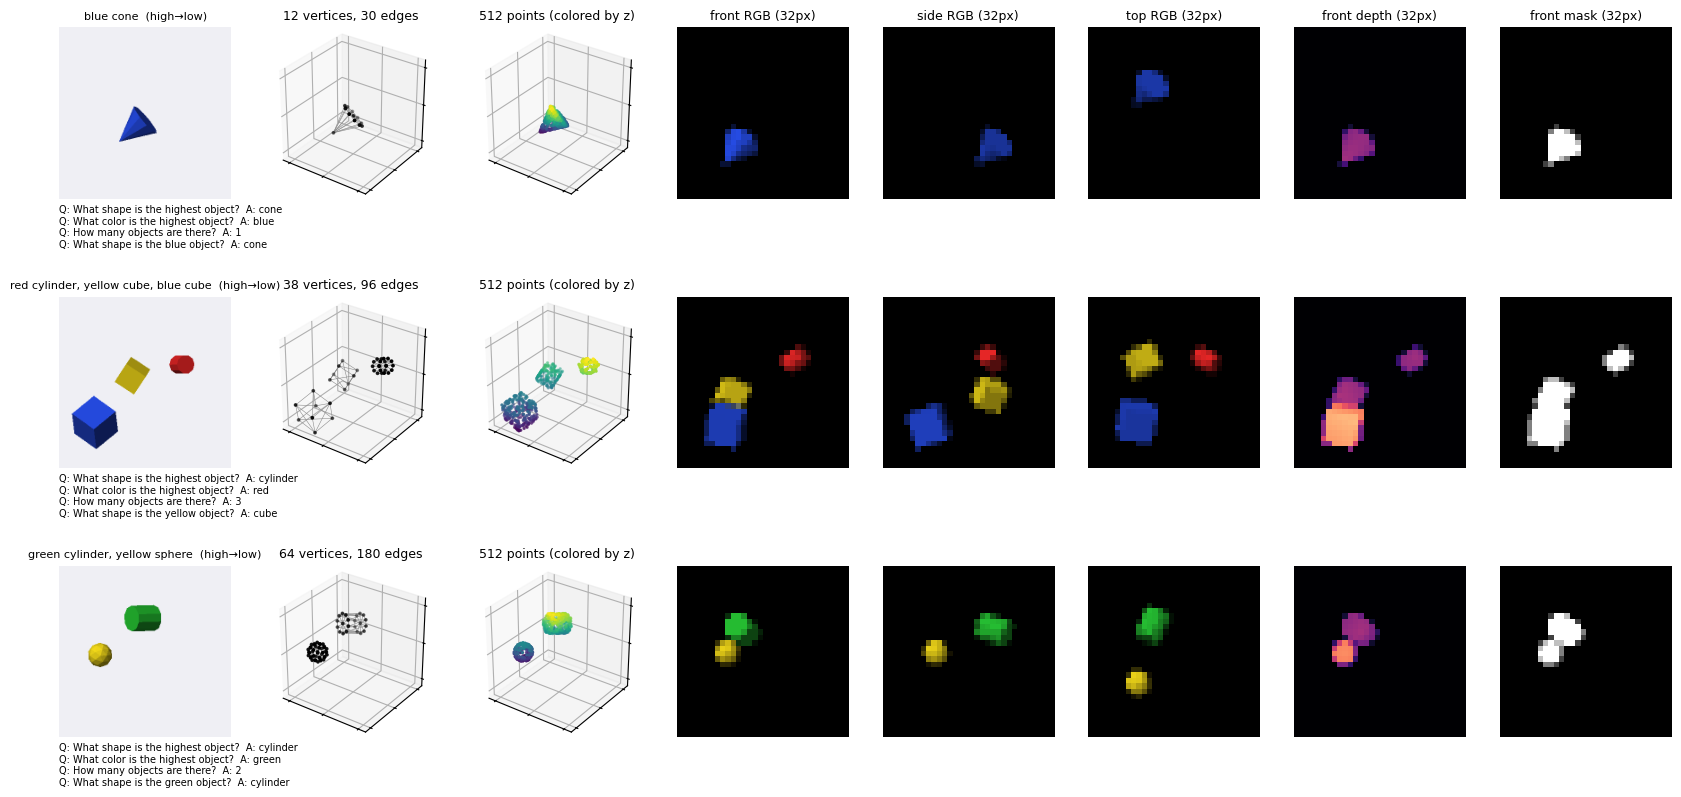

shape           majority-class acc 0.23  (5 answers)
color           majority-class acc 0.30  (4 answers)
count           majority-class acc 0.36  (3 answers)
shape_of_color  majority-class acc 0.24  (5 answers)


In [4]:
# ---------- Look at the data: what each encoder actually receives ----------
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection

def _setup3d(ax, title):
    d = np.asarray(HERO_DIR, float)
    ax.view_init(elev=np.degrees(np.arctan2(d[2], np.hypot(d[0], d[1]))), azim=np.degrees(np.arctan2(d[1], d[0])))
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_zlim(-1.2, 1.2); ax.set_box_aspect((1, 1, 1))
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([]); ax.set_title(title, fontsize=9)

def show_examples(n=3, seed=123, hero_res=192, save="scene_examples.png"):
    """Regenerates n scenes with the same functions as build_split and plots every model input next to a
    high-res oblique render (the render is for humans only; the model never sees it)."""
    rng = np.random.default_rng(seed)
    cols = ["3D render (oblique, for humans)", "mesh graph (GIN input)", "point cloud xyz (PointNet input)",
            "front RGB", "side RGB", "top RGB", "front depth", "front mask"]
    fig = plt.figure(figsize=(2.6 * len(cols), 3.3 * n))
    for row in range(n):
        objs = make_scene(rng)
        qa = [make_question(objs, rng, task=t)[1:] for t in TASKS]
        mx, me = to_mesh_graph(objs, CFG["v_max"])
        pts, _ = to_points(objs, CFG["n_points"], rng)
        views = to_views(objs, CFG["view_res"])
        hero = render(objs, look_from(HERO_DIR), hero_res, extent=1.6, ssaa=2)
        p = lambda c: fig.add_subplot(n, len(cols), row * len(cols) + c + 1, **({"projection": "3d"} if c in (1, 2) else {}))

        ax = p(0)
        bg = np.array([0.94, 0.94, 0.96])[:, None, None]
        ax.imshow((hero["rgb"] + (1 - hero["cov"]) * bg).transpose(1, 2, 0)); ax.axis("off")
        ax.set_title(", ".join(f"{o['color']} {o['shape']}" for o in sorted(objs, key=lambda o: -o["z"])) + "  (high→low)", fontsize=8)
        ax.text(0.0, -0.03, "\n".join(f"Q: {q}  A: {a}" for q, a in qa), transform=ax.transAxes, va="top", fontsize=7)

        ax = p(1); xyz = mx[:, :3]
        ax.add_collection3d(Line3DCollection(xyz[me.astype(int)], colors="0.55", linewidths=0.4))
        ax.scatter(*xyz.T, s=3, c="k"); _setup3d(ax, f"{len(mx)} vertices, {len(me)} edges")

        ax = p(2)
        ax.scatter(*pts.T, s=2, c=pts[:, 2], cmap="viridis"); _setup3d(ax, f"{len(pts)} points (colored by z)")

        for vi, name in enumerate(VIEW_CAMS):
            ax = p(3 + vi); ax.imshow(views[vi, :3].transpose(1, 2, 0), interpolation="nearest"); ax.axis("off")
        ax = p(6); ax.imshow(views[0, 3], cmap="magma", vmin=0, vmax=1, interpolation="nearest"); ax.axis("off")
        ax = p(7); ax.imshow(views[0, 4], cmap="gray", vmin=0, vmax=1, interpolation="nearest"); ax.axis("off")
        if row == 0:
            for c in range(3, len(cols)): fig.axes[c].set_title(f"{cols[c]} ({CFG['view_res']}px)", fontsize=9)
    plt.tight_layout(h_pad=3.5)
    if save: plt.savefig(save, dpi=150, bbox_inches="tight")
    plt.show()

show_examples()

# chance levels, so the trained numbers can be read against them
for t in TASKS:
    ans = [ex["a"] for ex in test_data if ex["task"] == t]
    vals, cnt = np.unique(ans, return_counts=True)
    print(f"{t:15s} majority-class acc {cnt.max() / len(ans):.2f}  ({len(vals)} answers)")

## 4. Shallow encoders, aggregators (Q-Former / MLP), budget matching
`match_budget` picks the width so that **encoders + aggregator + output projection** hit the target parameter count (LLM excluded). Each representation gets its own LayerNorm so no encoder dominates by scale.

In [5]:
# ---------- Shallow encoders ----------
class PointEnc(nn.Module):
    """Mini PointNet: shared MLP per point, max-pooled into G local groups -> G tokens."""
    def __init__(self, w, G=32):
        super().__init__(); self.G = G
        self.mlp = nn.Sequential(nn.Linear(3, w), nn.GELU(), nn.Linear(w, w), nn.GELU(), nn.Linear(w, w))
        self.pos = nn.Linear(3, w)
    def forward(self, pts):                                    # (B, N, 3)
        B, N, _ = pts.shape
        centers = pts[:, :self.G]                              # points are pre-shuffled -> random centers
        assign = torch.cdist(pts, centers).argmin(-1)          # (B, N)
        h = self.mlp(pts)
        tok = torch.full((B, self.G, h.size(-1)), -1e4, device=pts.device, dtype=h.dtype)
        tok = tok.scatter_reduce(1, assign[..., None].expand_as(h), h, reduce="amax", include_self=True)
        return tok + self.pos(centers), torch.zeros(B, self.G, dtype=torch.bool, device=pts.device)

class ViewEnc(nn.Module):
    """Small CNN shared across views; each view -> 4x4 spatial tokens (pooled, so any view_res works)."""
    def __init__(self, w, n_views=3):
        super().__init__()
        c = max(8, w // 2)
        self.cnn = nn.Sequential(nn.Conv2d(5, c, 3, padding=1), nn.GELU(),
                                 nn.Conv2d(c, w, 3, stride=2, padding=1), nn.GELU(),
                                 nn.Conv2d(w, w, 3, stride=2, padding=1), nn.AdaptiveAvgPool2d(4))
        self.pos = nn.Parameter(torch.randn(n_views * 16, w) * 0.02)
    def forward(self, views):                                  # (B, V, 5, H, W)
        B, V = views.shape[:2]
        h = self.cnn(views.flatten(0, 1))                      # (B*V, w, 4, 4)
        tok = h.flatten(2).transpose(1, 2).reshape(B, V * 16, -1) + self.pos
        return tok, torch.zeros(B, tok.size(1), dtype=torch.bool, device=views.device)

class MeshEnc(nn.Module):
    """Dense GIN on the mesh vertex graph -> one token per vertex."""
    def __init__(self, w, layers=2):
        super().__init__()
        self.inp = nn.Linear(6, w)
        self.eps = nn.Parameter(torch.zeros(layers))
        self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(w, w), nn.GELU(), nn.Linear(w, w)) for _ in range(layers)])
    def forward(self, x, adj, pad):                            # (B,V,6), (B,V,V), (B,V) True=pad
        h = self.inp(x)
        for e, mlp in zip(self.eps, self.mlps):
            h = h + mlp((1 + e) * h + adj @ h)
            h = h.masked_fill(pad[..., None], 0)
        return h, pad

ENCODERS = {"point": PointEnc, "view": ViewEnc, "mesh": MeshEnc}

# ---------- Aggregators ----------
class QFormerAgg(nn.Module):
    def __init__(self, d, K, layers=1, heads=4):
        super().__init__()
        self.q = nn.Parameter(torch.randn(K, d) * 0.02)
        self.layers = nn.ModuleList([nn.TransformerDecoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
                                     for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
    def forward(self, mem, pad):
        z = self.q.expand(mem.size(0), -1, -1)
        for l in self.layers: z = l(z, mem, memory_key_padding_mask=pad)
        return self.norm(z)

class MLPAgg(nn.Module):
    """Per-representation masked mean+max pooling -> MLP -> K tokens."""
    def __init__(self, d, K, n_reps):
        super().__init__(); self.K, self.d = K, d
        self.mlp = nn.Sequential(nn.Linear(2 * d * n_reps, 2 * d), nn.GELU(), nn.Linear(2 * d, K * d))
    def forward(self, toks, pads):                             # lists per representation
        feats = []
        for t, p in zip(toks, pads):
            keep = (~p).float()[..., None]
            mean = (t * keep).sum(1) / keep.sum(1).clamp(min=1)
            mx = t.masked_fill(p[..., None], -1e4).max(1).values * (keep.sum(1) > 0)
            feats += [mean, mx]
        return self.mlp(torch.cat(feats, -1)).view(-1, self.K, self.d)

class MultiRepAdaptor(nn.Module):
    def __init__(self, reps, w, agg="qformer", K=16, llm_dim=896, agg_layers=1):
        super().__init__()
        self.reps, self.agg_type = reps, agg
        self.enc = nn.ModuleDict({r: ENCODERS[r](w) for r in reps})
        self.norm = nn.ModuleDict({r: nn.LayerNorm(w) for r in reps})   # put every representation on the same scale
        self.type_emb = nn.Parameter(torch.randn(len(reps), w) * 0.02)
        self.agg = QFormerAgg(w, K, agg_layers) if agg == "qformer" else MLPAgg(w, K, len(reps))
        self.out = nn.Linear(w, llm_dim)
    def forward(self, batch, drop=None):                       # drop: (B, n_reps) bool, True = representation removed
        toks, pads = [], []
        for i, r in enumerate(self.reps):
            if r == "point": t, p = self.enc[r](batch["points"])
            if r == "view":  t, p = self.enc[r](batch["views"])
            if r == "mesh":  t, p = self.enc[r](batch["mesh_x"], batch["adj"], batch["mesh_pad"])
            if drop is not None: p = p | drop[:, i:i + 1]
            toks.append(self.norm[r](t) + self.type_emb[i]); pads.append(p)
        if self.agg_type == "qformer":
            mem, pad = torch.cat(toks, 1), torch.cat(pads, 1)
            z = self.agg(mem.masked_fill(pad[..., None], 0), pad)
        else:
            z = self.agg(toks, pads)
        return self.out(z)                                     # (B, K, llm_dim)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def match_budget(reps, agg, target, llm_dim=896, K=16):
    """Pick the encoder/aggregator width whose trainable-parameter count is closest to `target`."""
    best = None
    for w in range(16, 1025, 8):
        n = n_params(MultiRepAdaptor(reps, w, agg, K, llm_dim))
        if best is None or abs(n - target) < abs(best[1] - target): best = (w, n)
        if n > target * 1.5: break
    return best   # (width, n_params)

## 5. Frozen LLM

In [6]:
# ---------- Frozen LLM ----------
from transformers import AutoModelForCausalLM, AutoTokenizer
tok = AutoTokenizer.from_pretrained(CFG["llm_name"])
llm = AutoModelForCausalLM.from_pretrained(CFG["llm_name"], torch_dtype=torch.float32).to(device)
llm.requires_grad_(False); llm.eval()
print("LLM hidden size:", llm.config.hidden_size)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM hidden size: 896


## 6. Batching, training, evaluation
Soft tokens go in through `inputs_embeds`; loss only on answer tokens. Do **not** wrap the LLM forward in `torch.no_grad()` during training — gradients must flow through the frozen LLM into the adaptor.

Speed: the LLM runs under fp16 autocast, and the 152k-vocab LM head (~27% of the LLM's parameters) is applied only at the positions that predict answer tokens. Both leave the loss and the exact-match metric unchanged.

In [7]:
# ---------- Batching ----------
LLM_DIM = llm.config.hidden_size
embed = llm.get_input_embeddings()
EOS = tok.eos_token_id

def encode_text(ex):
    p = tok(f"Question: {ex['q']} Answer:", add_special_tokens=False)["input_ids"]
    a = tok(" " + ex["a"], add_special_tokens=False)["input_ids"] + [EOS]
    return p, a

def collate(exs):
    B, V = len(exs), CFG["v_max"]
    mesh_x = torch.zeros(B, V, 6); adj = torch.zeros(B, V, V); mesh_pad = torch.ones(B, V, dtype=torch.bool)
    for i, ex in enumerate(exs):
        n = len(ex["mesh_x"]); mesh_x[i, :n] = torch.from_numpy(ex["mesh_x"]); mesh_pad[i, :n] = False
        e = torch.from_numpy(ex["mesh_e"].astype(np.int64)); adj[i, e[:, 0], e[:, 1]] = 1; adj[i, e[:, 1], e[:, 0]] = 1
    texts = [encode_text(ex) for ex in exs]
    L = max(len(p) + len(a) for p, a in texts)
    ids = torch.full((B, L), EOS, dtype=torch.long); labels = torch.full((B, L), -100, dtype=torch.long)
    attn = torch.zeros(B, L, dtype=torch.long)
    for i, (p, a) in enumerate(texts):
        ids[i, :len(p) + len(a)] = torch.tensor(p + a); labels[i, len(p):len(p) + len(a)] = torch.tensor(a)
        attn[i, :len(p) + len(a)] = 1
    return dict(points=torch.from_numpy(np.stack([ex["points"] for ex in exs])),
                views=torch.from_numpy(np.stack([ex["views"] for ex in exs])),
                mesh_x=mesh_x, adj=adj, mesh_pad=mesh_pad, ids=ids, labels=labels, attn=attn,
                task=[ex["task"] for ex in exs])

def to_dev(b): return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in b.items()}

def answer_logits(model, b, drop=None):
    """[soft tokens; prompt; answer] -> frozen LLM -> logits only where the next token is an answer token.
    Returns (logits (n, vocab) fp32, targets (n,), example index (n,))."""
    K = CFG["K"]
    with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
        soft = model(b, drop)                                  # (B, K, H)
        x = torch.cat([soft, embed(b["ids"])], 1)
        attn = torch.cat([torch.ones(soft.shape[:2], dtype=b["attn"].dtype, device=device), b["attn"]], 1)
        h = llm.model(inputs_embeds=x, attention_mask=attn).last_hidden_state     # (B, K+L, H), final norm applied
        sel = b["labels"] != -100                              # ids position i is predicted from position K-1+i
        logits = llm.lm_head(h[:, K - 1:-1][sel])
    return logits.float(), b["labels"][sel], sel.nonzero()[:, 0]

def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=AMP)
    except (AttributeError, TypeError): return torch.cuda.amp.GradScaler(enabled=AMP)

# ---------- Train / eval ----------
def train(model, data, cfg=CFG, log_every=50, eval_data=None):
    """Returns the learning curve: test accuracy on `eval_data` after every epoch."""
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scaler = make_scaler(); curve = []
    steps = cfg["epochs"] * math.ceil(len(data) / cfg["batch_size"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, cfg["lr"], total_steps=steps, pct_start=0.05)
    model.train(); step = 0
    for ep in range(cfg["epochs"]):
        idx = np.random.permutation(len(data))
        for s in range(0, len(data), cfg["batch_size"]):
            b = to_dev(collate([data[i] for i in idx[s:s + cfg["batch_size"]]]))
            drop = None
            if len(model.reps) > 1 and cfg["rep_dropout"] > 0:
                drop = torch.rand(len(b["ids"]), len(model.reps), device=device) < cfg["rep_dropout"]
                drop[drop.all(1), 0] = False                    # always keep at least one representation
            logits, tgt, _ = answer_logits(model, b, drop)
            loss = F.cross_entropy(logits, tgt)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            sched.step(); step += 1
            if step % log_every == 0: print(f"  ep {ep} step {step}/{steps} loss {loss.item():.3f}")
        if eval_data is not None:
            curve.append(dict(epoch=ep + 1, **evaluate(model, eval_data)))
            print(f"  -- epoch {ep + 1}: " + " ".join(f"{k} {v:.2f}" for k, v in curve[-1].items() if k != "epoch"))
    return curve

@torch.no_grad()
def evaluate(model, data, drop_reps=()):
    """Exact match via teacher forcing: correct iff every answer token (incl. EOS) is the argmax,
    which is exactly what greedy decoding would output."""
    model.eval(); hits = {}
    for s in range(0, len(data), 64):
        b = to_dev(collate(data[s:s + 64]))
        drop = None
        if drop_reps:
            drop = torch.zeros(len(b["ids"]), len(model.reps), dtype=torch.bool, device=device)
            for r in drop_reps: drop[:, model.reps.index(r)] = True
        logits, tgt, ex = answer_logits(model, b, drop)
        wrong = torch.zeros(len(b["ids"]), device=device).index_add_(0, ex, (logits.argmax(-1) != tgt).float())
        ok = wrong == 0
        for t, o in zip(b["task"], ok.tolist()): hits.setdefault(t, []).append(o)
    model.train()
    res = {t: float(np.mean(v)) for t, v in hits.items()}
    res["avg"] = float(np.mean(list(res.values())))
    return res

## 7. Budget sweep
Results are appended to `results.json` after every run, so the cell can be re-run after a Colab disconnect.

In [ ]:
# ---------- Budget sweep ----------
BUDGETS = [1e6, 0.5e6]                 # trainable params (encoders + aggregator), LLM excluded; 1M first so the
                                            # draft has one complete budget even if the sweep is cut short
SETTINGS = {                                 # name -> (representations, aggregator)
    "point only": (["point"], "qformer"),
    "ours (all, Q-Former)": (["mesh", "point", "view"], "qformer"),
    "view only":  (["view"], "qformer"),
    "mesh only":  (["mesh"], "qformer"),
    "ours (all, MLP)":      (["mesh", "point", "view"], "mlp"),
}
RESULTS_PATH = "results.json"
results = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else []   # resume after a Colab disconnect
TAG = f"ep{CFG['epochs']}_amp{int(AMP)}_res{CFG['view_res']}"      # runs with other settings are kept but not mixed in
done = {(r["setting"], r["budget"]) for r in results if r.get("tag") == TAG}

for budget in BUDGETS:
    for name, (reps, agg) in SETTINGS.items():
        if (name, budget) in done: continue
        set_seed(CFG["seed"])
        w, n = match_budget(reps, agg, budget, LLM_DIM, CFG["K"])
        model = MultiRepAdaptor(reps, w, agg, CFG["K"], LLM_DIM).to(device)
        print(f"\n== {name} | budget {budget/1e6:.1f}M -> width {w}, {n/1e6:.2f}M params")
        t0 = time.time(); curve = train(model, train_data, eval_data=test_data[:CFG["curve_n"]])
        res = evaluate(model, test_data); secs = time.time() - t0
        print({k: round(v, 3) for k, v in res.items()}, f"({secs:.0f}s)")
        results.append(dict(setting=name, budget=budget, width=w, params=n, tag=TAG, secs=secs, curve=curve, **res))
        json.dump(results, open(RESULTS_PATH, "w"), indent=1)


== point only | budget 1.0M -> width 232, 0.97M params


/tmp/ipykernel_647/1233426572.py:67: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step(); step += 1


  ep 0 step 50/1504 loss 2.977
  ep 0 step 100/1504 loss 0.760
  ep 0 step 150/1504 loss 0.786
  -- epoch 1: shape 0.13 color 0.17 count 0.49 shape_of_color 0.17 avg 0.24
  ep 1 step 200/1504 loss 0.607
  ep 1 step 250/1504 loss 0.612
  ep 1 step 300/1504 loss 0.559
  ep 1 step 350/1504 loss 0.558
  -- epoch 2: shape 0.15 color 0.31 count 0.69 shape_of_color 0.13 avg 0.32
  ep 2 step 400/1504 loss 0.558
  ep 2 step 450/1504 loss 0.661
  ep 2 step 500/1504 loss 0.619
  ep 2 step 550/1504 loss 0.606
  -- epoch 3: shape 0.24 color 0.25 count 0.76 shape_of_color 0.19 avg 0.36
  ep 3 step 600/1504 loss 0.588
  ep 3 step 650/1504 loss 0.581
  ep 3 step 700/1504 loss 0.575
  ep 3 step 750/1504 loss 0.506
  -- epoch 4: shape 0.24 color 0.20 count 0.77 shape_of_color 0.24 avg 0.36
  ep 4 step 800/1504 loss 0.561
  ep 4 step 850/1504 loss 0.608
  ep 4 step 900/1504 loss 0.402
  -- epoch 5: shape 0.17 color 0.33 count 0.76 shape_of_color 0.32 avg 0.40
  ep 5 step 950/1504 loss 0.564
  ep 5 step 1

KeyboardInterrupt: 

## 8. Results

,setting,budget,params,shape,color,count,shape_of_color,avg
0,point only,1000000.0,973440,0.227,0.227,0.740,0.240,0.358
1,"ours (all, Q-Former)",1000000.0,972738,0.787,0.800,0.880,0.667,0.783
2,view only,1000000.0,968016,0.367,0.753,0.947,0.293,0.590
3,mesh only,1000000.0,1015394,0.993,0.260,0.813,0.667,0.683
4,"ours (all, MLP)",1000000.0,1037338,0.867,0.893,0.947,0.633,0.835
5,point only,500000.0,510336,0.167,0.227,0.833,0.220,0.362
6,"ours (all, Q-Former)",500000.0,511842,0.820,0.453,0.887,0.573,0.683
7,view only,500000.0,488936,0.353,0.453,0.900,0.287,0.498
8,mesh only,500000.0,514202,0.993,0.247,0.787,0.680,0.677
9,"ours (all, MLP)",500000.0,488658,0.807,0.273,0.927,0.613,0.655


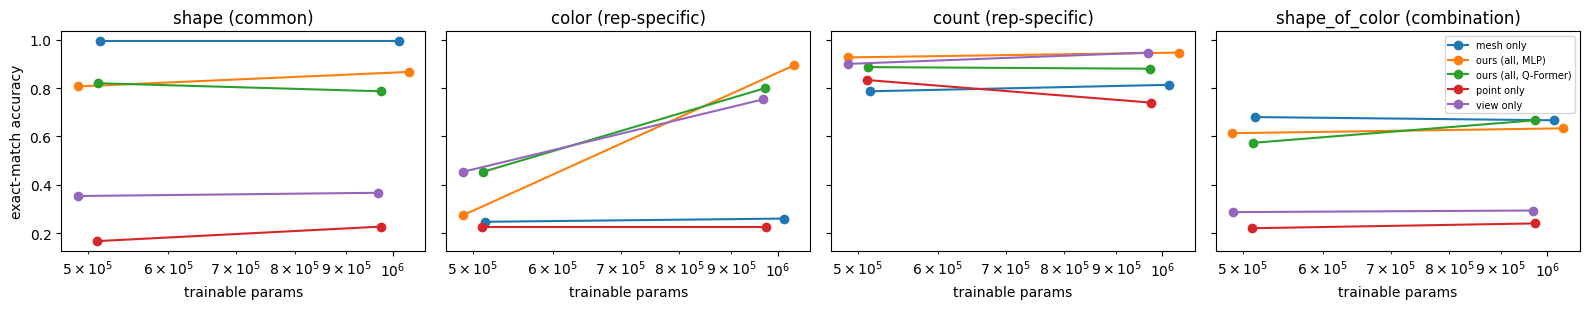

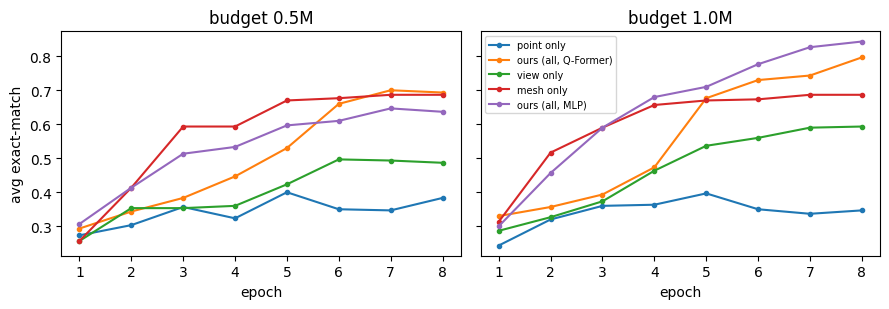

In [9]:
# ---------- Results ----------
import pandas as pd, matplotlib.pyplot as plt
df = pd.DataFrame([r for r in results if r.get("tag") == TAG])
cols = ["setting", "budget", "params"] + list(TASKS) + ["avg"]
display(df[cols].round(3))

fig, axes = plt.subplots(1, len(TASKS), figsize=(4 * len(TASKS), 3.2), sharey=True)
for ax, t in zip(axes, TASKS):
    for name, g in df.groupby("setting"):
        g = g.sort_values("params"); ax.plot(g["params"], g[t], marker="o", label=name)
    ax.set_xscale("log"); ax.set_title(f"{t} ({TASKS[t]})"); ax.set_xlabel("trainable params")
axes[0].set_ylabel("exact-match accuracy"); axes[-1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# learning curves (avg accuracy on the first curve_n test scenes after each epoch): flat at the end = converged
fig, axes = plt.subplots(1, df["budget"].nunique(), figsize=(4.5 * df["budget"].nunique(), 3.2), sharey=True, squeeze=False)
for ax, (budget, gb) in zip(axes[0], df.groupby("budget")):
    for _, r in gb.iterrows():
        ax.plot([c["epoch"] for c in r["curve"]], [c["avg"] for c in r["curve"]], marker=".", label=r["setting"])
    ax.set_title(f"budget {budget/1e6:.1f}M"); ax.set_xlabel("epoch")
axes[0, 0].set_ylabel("avg exact-match"); axes[0, -1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. (Optional) Textify baseline

In [12]:
# ---------- (Optional) Textify baseline: colored point cloud as text, zero-shot, same LLM ----------
def textify(ex, n=64):
    idx = np.linspace(0, len(ex["points"]) - 1, n).astype(int)        # points are already shuffled
    pts = " ".join(f"({x:.2f},{y:.2f},{z:.2f}) {c}" for (x, y, z), c in zip(ex["points"][idx], ex["point_colors"][idx]))
    return f"Colored 3D point cloud (x,y,z) color: {pts}\nQuestion: {ex['q']} Answer with one word."

NUM_WORDS = {"one": "1", "two": "2", "three": "3"}

@torch.no_grad()
def textify_zero_shot(data, n=100):
    hits = {}
    for ex in data[:n]:
        msgs = [{"role": "user", "content": textify(ex)}]
        # render the template to text, then tokenize: works on transformers 4.x and 5.x
        # (5.x returns a BatchEncoding from apply_chat_template(..., return_tensors="pt"), which generate() rejects)
        prompt = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
        enc = tok(prompt, return_tensors="pt", add_special_tokens=False).to(device)
        out = llm.generate(**enc, max_new_tokens=6, do_sample=False, pad_token_id=tok.eos_token_id)
        pred = tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip().lower()
        pred = pred.split()[0].strip(".,!\"'") if pred else ""
        pred = NUM_WORDS.get(pred, pred)                          # "three" -> "3" for the count task
        hits.setdefault(ex["task"], []).append(pred == ex["a"])
    res = {t: float(np.mean(v)) for t, v in hits.items()}; res["avg"] = float(np.mean(list(res.values())))
    return res

print("textify zero-shot:", textify_zero_shot(test_data))
print("tokens per textified prompt ≈", len(tok(textify(test_data[0]))["input_ids"]), "vs K =", CFG["K"])

textify zero-shot: {'shape': 0.08, 'color': 0.76, 'count': 0.0, 'shape_of_color': 0.08, 'avg': 0.22999999999999998}
tokens per textified prompt ≈ 1117 vs K = 16


## Notes from the CPU sanity check (no LLM; linear probe on adaptor outputs, 3k train scenes)
_Measured with the old renderer (16px unshaded point splatting); re-check with the rasterized 32px views._

| setting | shape | color | count | shape_of_color |
|---|---|---|---|---|
| view only | 0.27 | 0.97 | 0.94 | 0.25 |
| mesh only | 0.87 | 0.25 | 0.74 | 0.63 |
| point only | 0.21 | 0.26 | 0.75 | 0.28 |
| all, Q-Former, 12 epochs, no LayerNorm | 0.89 | 0.23 | 0.87 | 0.65 |
| all, Q-Former, 24 epochs, LayerNorm, rep-dropout 0.3 | 0.93 | 0.89 | 0.87 | 0.67 |

- Representations do carry different information (views → color, mesh → shape), as designed.
- Multi-rep models converge more slowly, and representation dropout slows them further → train to convergence, plot learning curves, don't compare at a fixed small epoch count.
- **Open issue:** `shape_of_color` stays ~0.65 for every setting. Color (views) and shape (mesh) both arrive, but nothing tells the aggregator which view pixel and which mesh vertex belong to the same object. Candidate fixes: shared 3D positional encoding for all tokens (unproject view pixels to 3D), question-conditioned queries.
- The point encoder is weak on shape (near chance) — worth tuning (more groups, local coordinates relative to group centers).
